# Low-resolution double-basin PG prototype

This production-oriented notebook solves an idealized version of the attached two-basin sketch. Two deep bowls are separated by a shallow central ridge that extends westward from the eastern shelf, leaving a deeper western gateway analogous to Fram Strait. The outer shallow region represents a continental shelf.

The calculation uses a constant Coriolis parameter (an $f$ plane) and cyclonic wind-stress cells over both basins. Expensive adjoint, perturbation, and external-theory checks from `PG_API_Example.ipynb` are omitted. The depth-integrated momentum and three equivalent vorticity-budget closure diagnostics are retained.

In [10]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy
using Plots
using Test

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


## Fast prototype controls

Increase `mesh_resolution`, `horizontal_points`, `vertical_points`, and `diagnostic_points` only after the geometry and forcing have been finalized. Disk output is disabled by default.

In [11]:
# Low resolution testing:
# mesh_resolution = 0.16
# horizontal_points = 33
# vertical_points = 25
# diagnostic_points = 17
# SAVE_OUTPUT = false

# Medium resolution testing:
mesh_resolution = 0.08
horizontal_points = 65
vertical_points = 49
diagnostic_points = 33
SAVE_OUTPUT = false

output_path(name) = SAVE_OUTPUT ? joinpath(@__DIR__, name) : nothing

output_path (generic function with 1 method)

## Idealized double-basin geometry and forcing

The bathymetry is a shallow perimeter shelf plus northern and southern Gaussian deep basins. An elongated shallow Barents shelf projects westward across the central/eastern basin, leaving a narrow, basin-depth Fram Strait channel in the western third. A smooth elliptical taper forces every deep feature to vanish at the outer boundary. All depth derivatives are supplied analytically. The two compact wind-stress cells have positive (cyclonic) curl near their basin centers.

In [ ]:
Lx, Ly = 2.0, 2.8
ax, ay = Lx / 2, Ly / 2
Ek = 0.02
Γ = 0.20
boundary = ellipse_boundary(ax, ay; points=64)
parameters = PGParameters(Ek, Γ; viscosity=1.0, diffusivity=1.0)

gaussian(x, y, cx, cy, sx, sy) = exp(-((x - cx) / sx)^2 - ((y - cy) / sy)^2)
gaussian_x(x, y, cx, cy, sx, sy) =
    -2(x - cx) / sx^2 * gaussian(x, y, cx, cy, sx, sy)
gaussian_y(x, y, cx, cy, sx, sy) =
    -2(y - cy) / sy^2 * gaussian(x, y, cx, cy, sx, sy)

shelf_depth = 0.26
shelf_width = 0.18
north_basin = (amplitude=0.96, cx=0.01, cy=0.69, sx=0.62, sy=0.455)
south_basin = (amplitude=0.96, cx=0.01, cy=-0.69, sx=0.62, sy=0.455)
deep_basins = (north_basin, south_basin)

# This westward-deepening sigmoid is nearly flat over the Barents shelf.
# The outer taper closes it against the western shelf, making Fram Strait
# a saddle rather than a locally deepest hole.
fram_amplitude = 0.80
fram_transition = -0.55
fram_width = 0.17
fram_deepening(x) = fram_amplitude / (1 + exp((x - fram_transition) / fram_width))
fram_deepening_x(x) = -(fram_amplitude / fram_width) *
    exp((x - fram_transition) / fram_width) /
    (1 + exp((x - fram_transition) / fram_width))^2

elliptical_radius_squared(x, y) = (x / ax)^2 + (y / ay)^2
interior_taper(x, y) = 1 - exp(-((1 - elliptical_radius_squared(x, y)) / shelf_width)^2)
interior_taper_x(x, y) =
    -4x * (1 - elliptical_radius_squared(x, y)) / (ax^2 * shelf_width^2) *
    exp(-((1 - elliptical_radius_squared(x, y)) / shelf_width)^2)
interior_taper_y(x, y) =
    -4y * (1 - elliptical_radius_squared(x, y)) / (ay^2 * shelf_width^2) *
    exp(-((1 - elliptical_radius_squared(x, y)) / shelf_width)^2)

deepening(x, y) = sum(
    feature.amplitude * gaussian(x, y, feature.cx, feature.cy, feature.sx, feature.sy)
    for feature in deep_basins
) + fram_deepening(x)
deepening_x(x, y) = sum(
    feature.amplitude * gaussian_x(x, y, feature.cx, feature.cy, feature.sx, feature.sy)
    for feature in deep_basins
) + fram_deepening_x(x)
deepening_y(x, y) = sum(
    feature.amplitude * gaussian_y(x, y, feature.cx, feature.cy, feature.sx, feature.sy)
    for feature in deep_basins
)

depth(x, y) = shelf_depth + interior_taper(x, y) * deepening(x, y)
depth_x(x, y) =
    interior_taper_x(x, y) * deepening(x, y) + interior_taper(x, y) * deepening_x(x, y)
depth_y(x, y) =
    interior_taper_y(x, y) * deepening(x, y) + interior_taper(x, y) * deepening_y(x, y)

f0 = 1.0
stress_amplitude = 1e-3
wind_cells = (
    (cx=north_basin.cx, cy=north_basin.cy, sx=0.55, sy=0.52),
    (cx=south_basin.cx, cy=south_basin.cy, sx=0.57, sy=0.50),
)
stress_envelope(x, y, cell) = gaussian(x, y, cell.cx, cell.cy, cell.sx, cell.sy)
wind_stress(x, y) = sum(
    stress_amplitude * stress_envelope(x, y, cell) *
    (-(y - cell.cy) / cell.sy + im * (x - cell.cx) / cell.sx)
    for cell in wind_cells
)
wind_stress_curl(x, y) = sum(
    stress_amplitude * stress_envelope(x, y, cell) * (
        (1 - 2((x - cell.cx) / cell.sx)^2) / cell.sx +
        (1 - 2((y - cell.cy) / cell.sy)^2) / cell.sy
    ) for cell in wind_cells
)

problem = PGProblem(
    parameters=parameters,
    depth=depth,
    depth_x=depth_x,
    depth_y=depth_y,
    coriolis=(x, y) -> f0,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> 0.0,
    wind_stress=wind_stress,
    wind_stress_curl=wind_stress_curl,
    restoring_buoyancy=(x, y, z) -> 1e-2z,
    surface_buoyancy=(x, y) -> 2e-3 * y / Ly,
    boundary=boundary,
)

PGProblem{PGParameters{Float64}, typeof(depth), var"#67#68", var"#69#70", var"#71#72", typeof(wind_stress), typeof(wind_stress_curl), var"#73#74", var"#75#76", typeof(depth_x), typeof(depth_y), Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#124#125"{Vector{Tuple{Float64, Float64}}}}(PGParameters{Float64}(0.02, 0.2, 1.0, 1.0), Main.depth, var"#67#68"(), var"#69#70"(), var"#71#72"(), Main.wind_stress, Main.wind_stress_curl, var"#73#74"(), var"#75#76"(), Main.depth_x, Main.depth_y, [(1.0, 0.0), (0.9951847266721969, 0.13722399646138483), (0.9807852804032304, 0.2731264508225795), (0.9569403357322088, 0.40639854815624726), (0.9238795325112867, 0.5357568053111257), (0.881921264348355, 0.6599554315563967), (0.8314696123025452, 0.777798326227443), (0.773010453362737, 0.8881505978291037), (0.7071067811865476, 0.9899494936611664), (0.6343932841636455, 1.0822146347078316)  …  (0.5555702330196018, -1.1640574572235636), (0.6343932841636456, -1.0822146347078316), (0.7071067811865474, -0.98

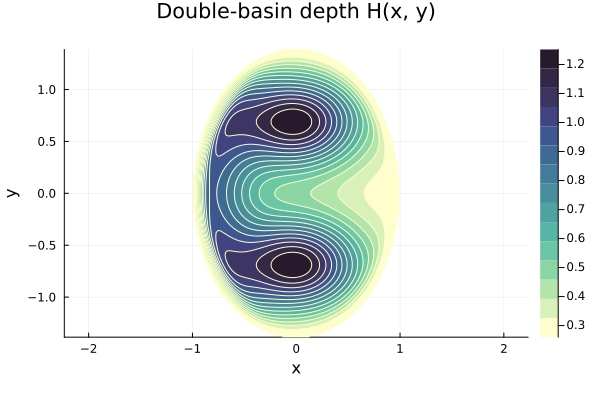

In [13]:
geometry_x = range(-0.99ax, 0.99ax; length=101)
geometry_y = range(-0.99ay, 0.99ay; length=141)
geometry_depth = [
    problem.inside(xx, yy) ? depth(xx, yy) : NaN
    for yy in geometry_y, xx in geometry_x
]
geometry_figure = contourf(
    geometry_x, geometry_y, geometry_depth;
    levels=14, color=:deep, aspect_ratio=:equal,
    xlabel="x", ylabel="y", title="Double-basin depth H(x, y)",
)
display(geometry_figure)

## Solve and sample

The pressure mesh and three-dimensional sampling grids are deliberately coarse for rapid iteration.

┌ Info: PG solve started
│   Ek = 0.02
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.08
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/double_basin_prototype_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:237
┌ Info: Starting generating surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 10%] Meshing curve 3 (Line)
Info    : [ 10%] Meshing curve 4 (Line)
Info    : [ 10%] Meshing curve 5 (Line)
Info    : [ 10%] Meshing curve 6 (Line)
Info    : [ 10%] Meshing curve 7 (Line)
Info    : [ 20%] Meshing curve 8 (Line)
Info    : [ 20%] Meshing curve 9 (Line)
Info    : [ 20%] Meshing curve 10 (Line)
Info    : [ 20%] Meshing curve 11 (Line)
Info    : [ 20%] Meshing curve 12 (Line)
Info    : [ 20%] Meshing curve 13 (Line)
Info    : [ 30%] Meshing curve 14 (Line)
Info    : [ 30%] Meshing curve 15 (Line)
Info    : [ 30%] Meshing curve 16 (Line)
Info    : [ 30%] Meshing curve 17 (Line)
Info    : [ 30%] Meshing curve 18 (Line)
Info    : [ 30%] Meshing curve 19 (Line)
Info    : [ 30%] Meshing curve 20 (Line)
Info    : [ 40%] Meshing curve 21 (Line)
Info    : [ 40%] Meshing curve 22 (Line)
Info    : [ 40%] Meshing curve 23 (Line)
Info    : [ 40%] Meshing curve 24 (Line)
I

┌ Info: Completed generating surface mesh
│   seconds = 0.026
│   allocated_mib = 0.01
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Surface-pres

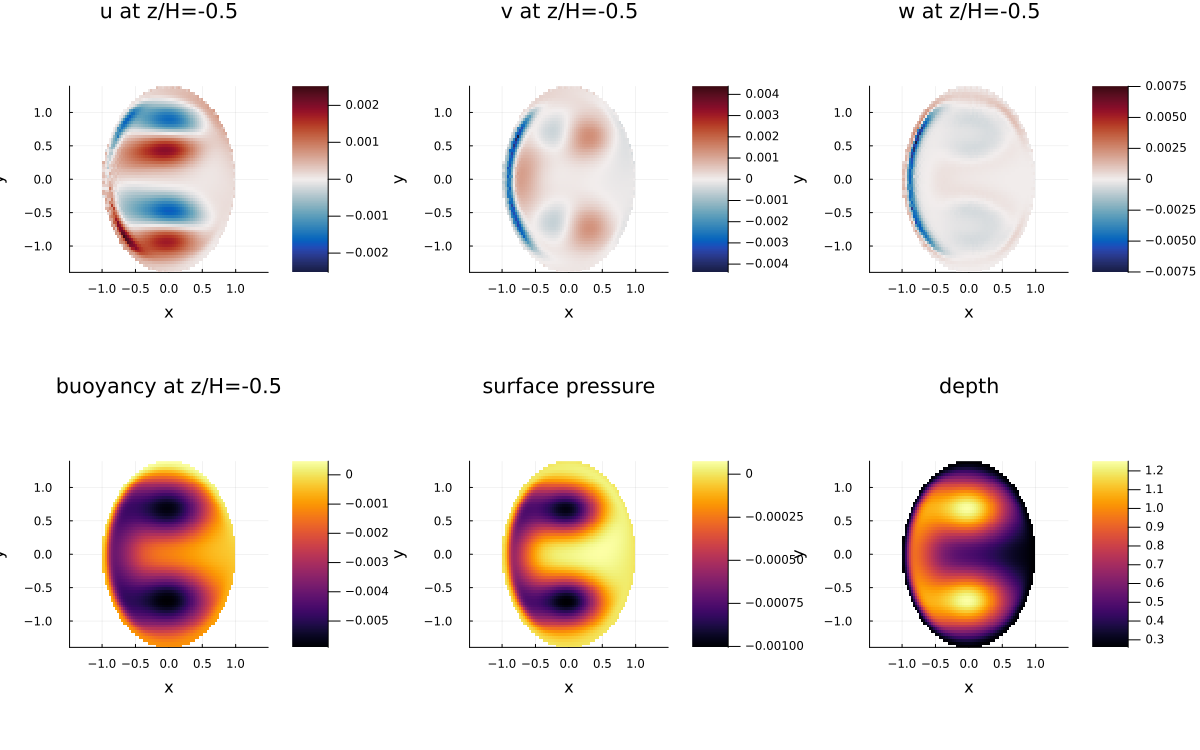

In [14]:
solution = solve_pg(
    problem;
    mesh_file=joinpath(@__DIR__, "double_basin_prototype_pressure.msh"),
    mesh_resolution=mesh_resolution,
    overwrite_mesh=true,
)

x = range(-0.98ax, 0.98ax; length=horizontal_points)
y = range(-0.98ay, 0.98ay; length=horizontal_points)
maximum_depth = maximum(depth(xx, yy) for yy in y, xx in x if problem.inside(xx, yy))
z = range(-maximum_depth, 0.0; length=vertical_points)
fields = sample_solution(solution, x, y, z)

solution_figure = plot_solution(
    fields;
    sigma_level=0.5,
    output=output_path("double_basin_solution.png"),
)
display(solution_figure)

if SAVE_OUTPUT
    display(write_solution(fields, joinpath(@__DIR__, "double_basin")))
end

## Shared diagnostic fields

All budget calculations reuse this modest diagnostic grid and the resulting stress and transport samples.

┌ Info: PG diagnostic calculation started
│   Nx = 33
│   Ny = 33
│   horizontal_points = 1089
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1766
┌ Info: Transport streamfunction solve started
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:370
┌ Info: Starting constructing streamfunction finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:12
┌ Info: Completed constructing streamfunction finite-element spaces
│   seconds = 0

(streamfunction = (finite_element_setup = (seconds = 0.009293333, allocated_mib = 1.8739166259765625, gc_seconds = 0.007437042), current_projection = (seconds = 36.053706167, allocated_mib = 1700.3580780029297, gc_seconds = 0.072495), operator_assembly = (seconds = 0.005702042, allocated_mib = 3.43035888671875, gc_seconds = 0.0), linear_solve = (seconds = 0.008638958, allocated_mib = 10.958099365234375, gc_seconds = 0.0), total_seconds = 36.11471509933472), bottom_stress_projection = (setup = (seconds = 0.000818208, allocated_mib = 0.97894287109375, gc_seconds = 0.0), interpolation = (seconds = 23.135313708, allocated_mib = 19994.406631469727, gc_seconds = 0.809839458), total_seconds = 23.164182901382446), sampling = (seconds = 5.5911125, allocated_mib = 692.148193359375, gc_seconds = 0.032708749), total_seconds = 65.29236197471619, wet_points = 897, points_per_second = 160.4331874917559, transport_projection_relative_l2 = 0.11562429935523459)

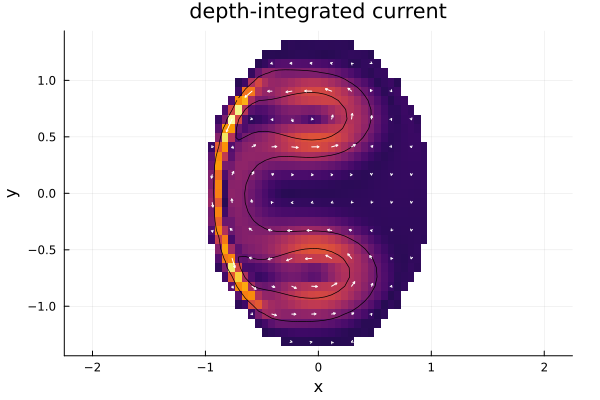

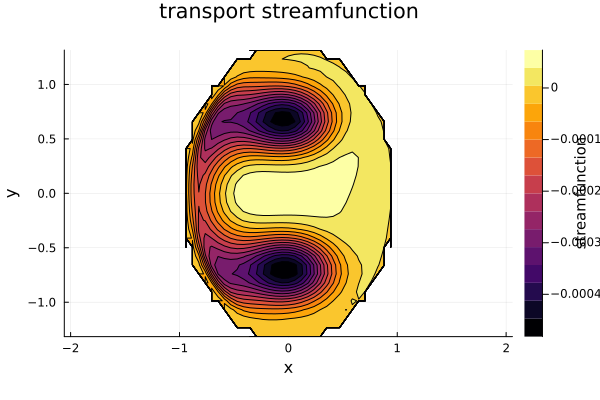

In [15]:
diagnostic_x = range(-0.94ax, 0.94ax; length=diagnostic_points)
diagnostic_y = range(-0.94ay, 0.94ay; length=diagnostic_points)
diagnostics = compute_diagnostics(solution, diagnostic_x, diagnostic_y)
display(performance_summary(diagnostics))

display(plot_depth_integrated_current(
    diagnostics; arrow_scale=0.70,
    output=output_path("double_basin_transport.png"),
))
display(plot_streamfunction(
    diagnostics;
    output=output_path("double_basin_streamfunction.png"),
))

## Budget closure diagnostics

Retain the depth-integrated momentum balance and the barotropic, depth-integrated, geostrophic-contour, and transport-divergence vorticity balances from the API example.

In [16]:
dim = compute_dim_diagnostics(solution, diagnostics)
barotropic_vorticity = compute_barotropic_vorticity_diagnostics(solution, diagnostics)
vorticity = compute_vorticity_diagnostics(solution, diagnostics)
gcvb = compute_geostrophic_contour_vorticity_diagnostics(solution, diagnostics)
tdvb = compute_transport_divergence_vorticity_diagnostics(solution, diagnostics)

closure = (
    momentum_x=dim.timings.x_relative_l2_residual,
    momentum_y=dim.timings.y_relative_l2_residual,
    barotropic_vorticity=barotropic_vorticity.timings.relative_l2_residual,
    depth_integrated_vorticity=vorticity.timings.relative_l2_residual,
    geostrophic_contour_vorticity=gcvb.timings.relative_l2_residual,
    transport_divergence_vorticity=tdvb.timings.relative_l2_residual,
)
display(closure)

┌ Info: DIM diagnostic calculation started
│   Nx = 33
│   Ny = 33
│   wet_points = 897
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1860
┌ Info: Starting sampling depth-integrated momentum terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: DIM diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 33
│   percent = 3.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1885
┌ Info: DIM diagnostic sampling progress
│   rows_complete

(momentum_x = 3.893719286633901e-5, momentum_y = 1.3654405149949763e-5, barotropic_vorticity = 0.932130982026887, depth_integrated_vorticity = 0.9995725175019163, geostrophic_contour_vorticity = 0.9331025845324871, transport_divergence_vorticity = 0.932130982026887)

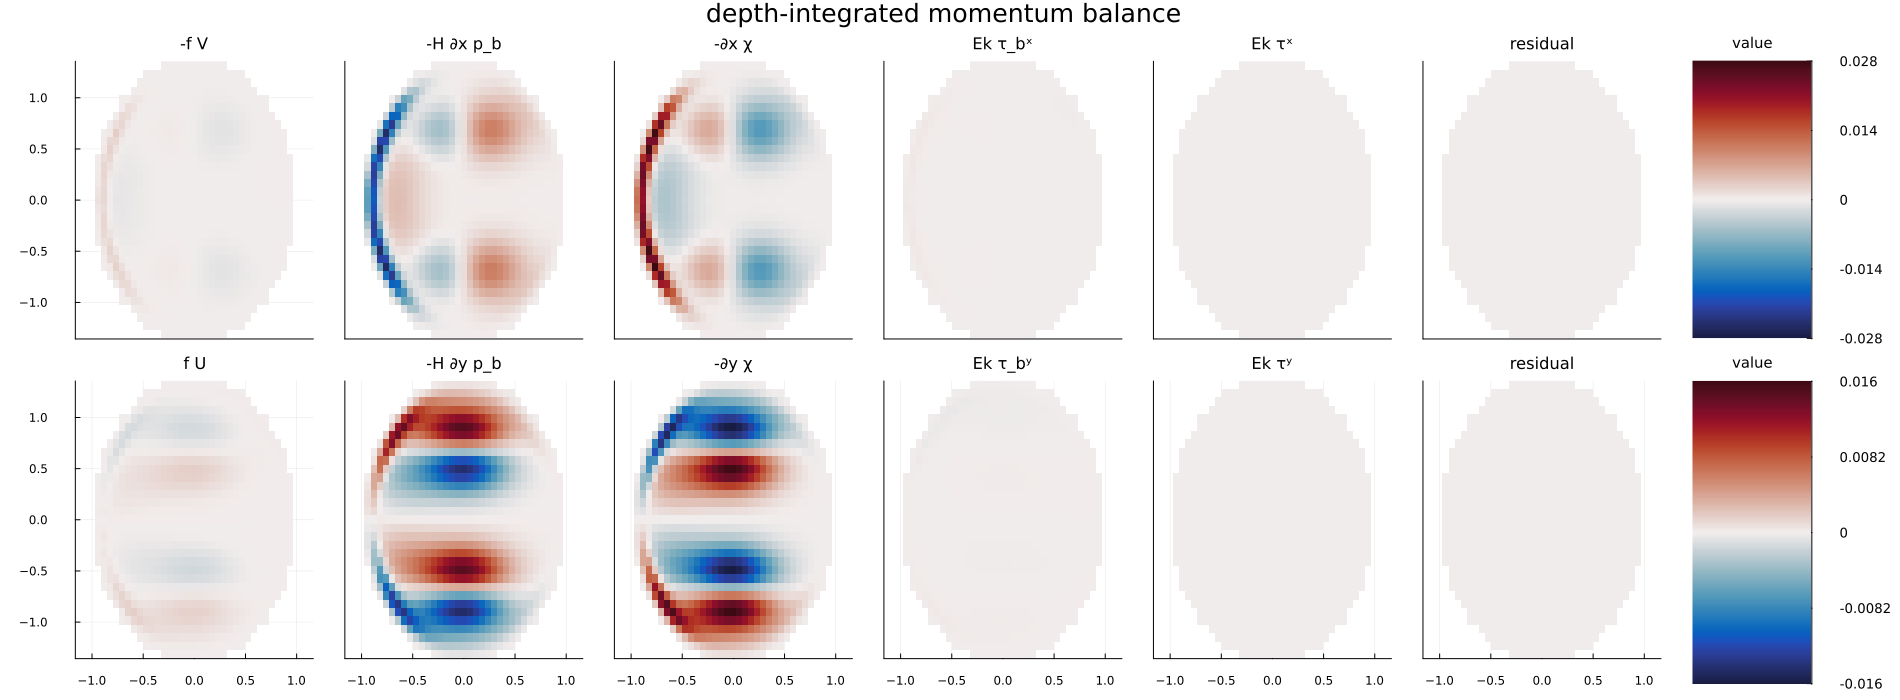

┌ Info: Plotting depth-integrated momentum balance
│   component = both
│   output = nothing
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:3180
┌ Info: Starting rendering DIM balance plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed rendering DIM balance plot
│   seconds = 0.013
│   allocated_mib = 2.92
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Plotting barotropic vorticity balance
│   output = n

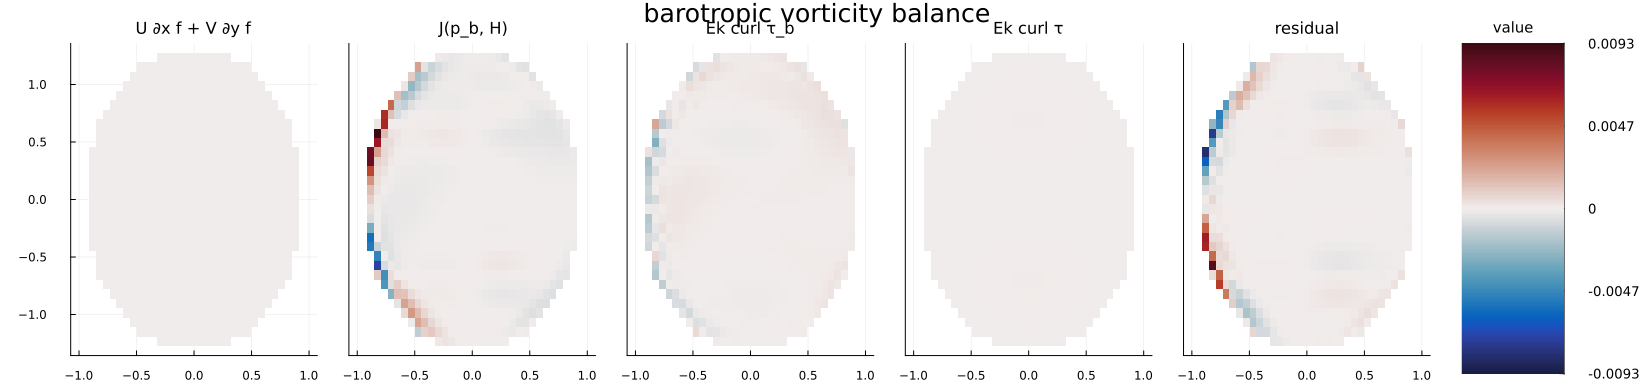

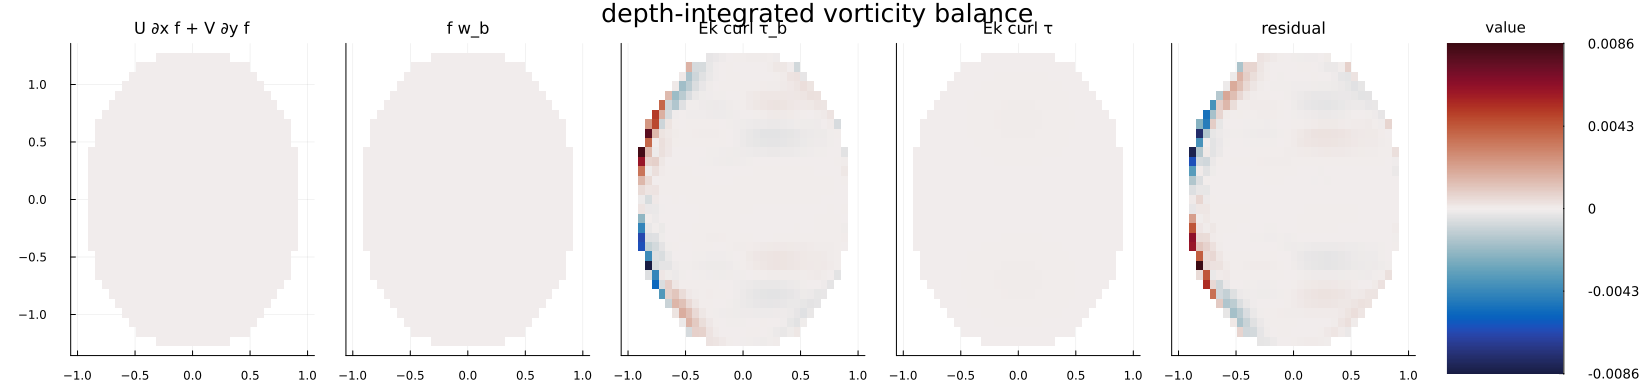

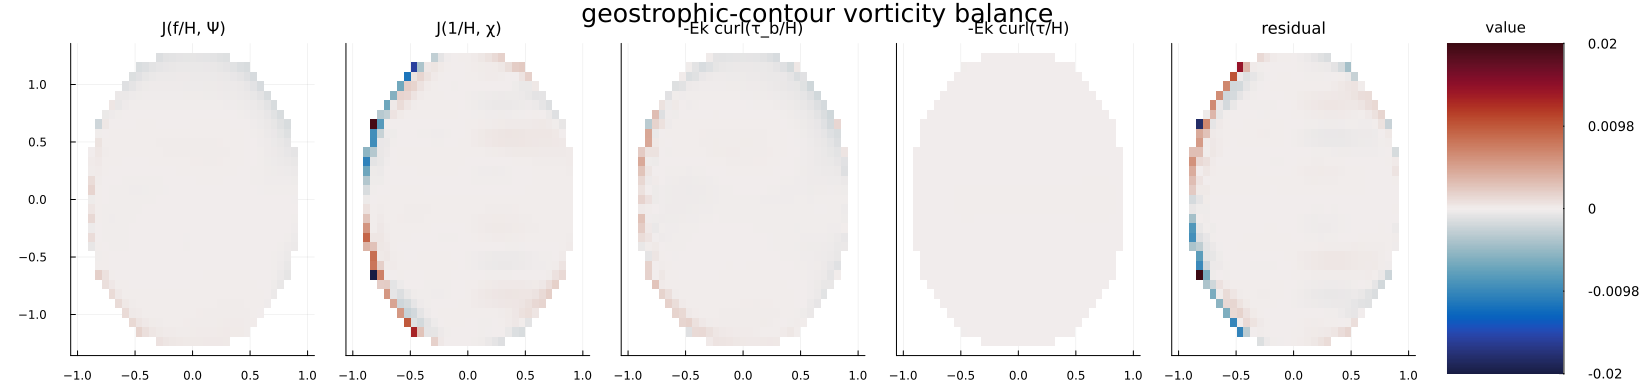

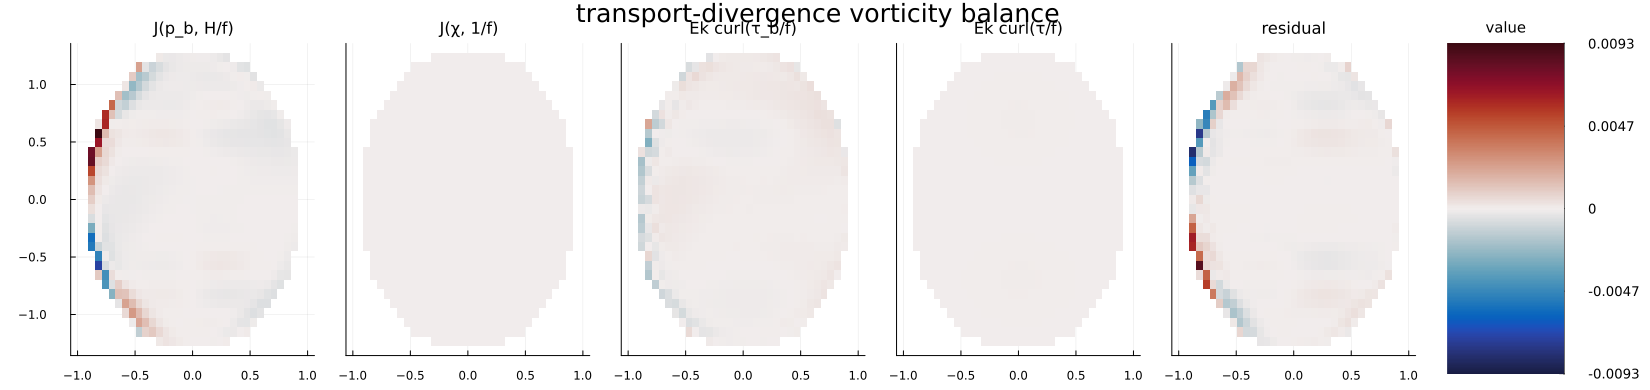

In [17]:
display(plot_dim_balance(
    dim; output=output_path("double_basin_dim_balance.png"),
))
display(plot_barotropic_vorticity_balance(
    barotropic_vorticity;
    output=output_path("double_basin_barotropic_vorticity_balance.png"),
))
display(plot_vorticity_balance(
    vorticity; output=output_path("double_basin_vorticity_balance.png"),
))
display(plot_geostrophic_contour_vorticity_balance(
    gcvb;
    output=output_path("double_basin_geostrophic_contour_vorticity_balance.png"),
))
display(plot_transport_divergence_vorticity_balance(
    tdvb;
    output=output_path("double_basin_transport_divergence_vorticity_balance.png"),
))

## Automated closure checks

These smoke tests catch failed or empty diagnostics without imposing a final production-resolution tolerance. Tight closure thresholds should be selected after the mesh and sampling resolution are increased.

In [18]:
@testset "Double-basin geometry" begin
    symmetry_x = range(-0.9ax, 0.9ax; length=17)
    symmetry_y = range(0.0, 0.9ay; length=17)
    @test all(
        isapprox(depth(xx, yy), depth(xx, -yy); rtol=1e-12, atol=1e-12)
        for xx in symmetry_x, yy in symmetry_y
    )

    barents_x = range(-Lx / 6, 0.95ax; length=65)
    barents_depth = [depth(xx, 0.0) for xx in barents_x]
    @test all(diff(barents_depth) .<= 1e-8)

    fram_x, fram_y, δ = -0.81, 0.0, 1e-3
    fram_xx = (depth(fram_x + δ, fram_y) - 2depth(fram_x, fram_y) +
        depth(fram_x - δ, fram_y)) / δ^2
    fram_yy = (depth(fram_x, fram_y + δ) - 2depth(fram_x, fram_y) +
        depth(fram_x, fram_y - δ)) / δ^2
    @test fram_xx < 0
    @test fram_yy > 0
    @test depth(fram_x, fram_y) < depth(north_basin.cx, north_basin.cy)
    @test depth(fram_x, fram_y) < depth(south_basin.cx, south_basin.cy)
end

@testset "PG budget closure smoke tests" begin
    @test count(diagnostics.wet) > 0
    @test count(barotropic_vorticity.wet) > 0
    @test count(vorticity.wet) > 0
    @test count(gcvb.wet) > 0
    @test count(tdvb.wet) > 0
    @test all(isfinite, values(closure))
end

Test Summary:         | Pass  Total  Time
Double-basin geometry |    6      6  0.0s
Test Summary:                 | Pass  Total  Time
PG budget closure smoke tests |    6      6  0.0s


Test.DefaultTestSet("PG budget closure smoke tests", false, true, false, "/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X21sZmlsZQ==.jl", 1.790434281723433e9, Random.Xoshiro(0x39ac8d3280aff72a, 0x361e1a817cec7c34, 0x58a8a905c627f7db, 0xda66b3180f76300b, 0x90210f7c4278935a), 6, 1.790434281723501e9, 0x01, ReentrantLock(), Any[])